Shape: (150, 4) -> (150, 2) | ratio: [0.9912126 0.0087874]


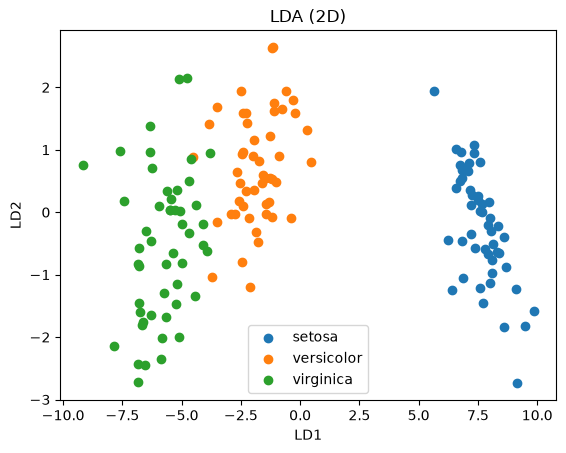

Accuracy: 1.0


In [1]:
# ===================== REVISION / ONE-SHOT: LDA =====================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_wine, load_breast_cancer, load_digits
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# 1) Load (CSV pattern: X = df.drop("target", axis=1); y = LabelEncoder().fit_transform(df["target"]))
iris = load_iris()
X, y = iris.data, iris.target

# 2) LDA as dimensionality reduction (needs y!). n_components <= min(classes - 1, features)
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X, y)
print("Shape:", X.shape, "->", X_lda.shape, "| ratio:", lda.explained_variance_ratio_)

# 3) 2D scatter by class
for i, name in enumerate(iris.target_names):
    plt.scatter(X_lda[y == i, 0], X_lda[y == i, 1], label=name)
plt.title("LDA (2D)"); plt.xlabel("LD1"); plt.ylabel("LD2"); plt.legend(); plt.show()

# 4) Binary data (breast cancer): only 1 component possible -> histogram per class
# for c in [0, 1]: plt.hist(X_lda[y == c, 0], bins=30, alpha=0.6, label=str(c))

# 5) LDA as classifier
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = LinearDiscriminantAnalysis().fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

# ---------------- VIVA NOTES ----------------
# LDA = supervised; finds axes that maximize between-class spread / within-class spread.
# Max components = min(n_classes - 1, n_features): iris/wine -> 2, breast cancer -> 1, digits -> 9.
# PCA keeps variance (ignores labels); LDA keeps class separation, so classes separate better.
# fit_transform(X, y) needs labels; text labels -> LabelEncoder.
# LDA is also a classifier (assumes Gaussian classes with shared covariance).
# Read plot: tight, far apart class groups = good separability.

### Q34

Apply Linear Discriminant Analysis (LDA) to the Iris dataset to reduce its dimensionality from 4 to 2 dimensions. You will visualize the LDA-reduced dataset in a 2D scatter plot using Matplotlib.

instructions:
- Load the Iris dataset
- Briefly explore the dataset to understand its structure. Print the shape of the dataset and the first few rows to get an overview of the features and target variable.
- Initialize the PCA object to reduce the dataset to 2 dimensions.
- Fit the LDA model to the Iris dataset and transform the dataset
- Use Matplotlib to create a scatter plot of the LDA-reduced dataset.
- Color the points based on their respective species (Setosa, Versicolor, Virginica) to visualize how well the LDA has separated the different classes.
- Add appropriate titles and labels to the axes of the plot.
- Include a legend to indicate which colors correspond to which species.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [3]:
# Load and explore
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = [iris.target_names[t] for t in iris.target]
print("Shape:", df.shape)
print(df.head())

Shape: (150, 5)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


In [4]:
# Question says "PCA object" here but means LDA (whole question is about LDA)
X = iris.data
y = iris.target
lda = LinearDiscriminantAnalysis(n_components=2)    # max = classes - 1 = 2
X_lda = lda.fit_transform(X, y)                     # LDA needs labels y
print("Reduced shape:", X_lda.shape)
print("Explained variance ratio:", lda.explained_variance_ratio_.round(3))

Reduced shape: (150, 2)
Explained variance ratio: [0.991 0.009]


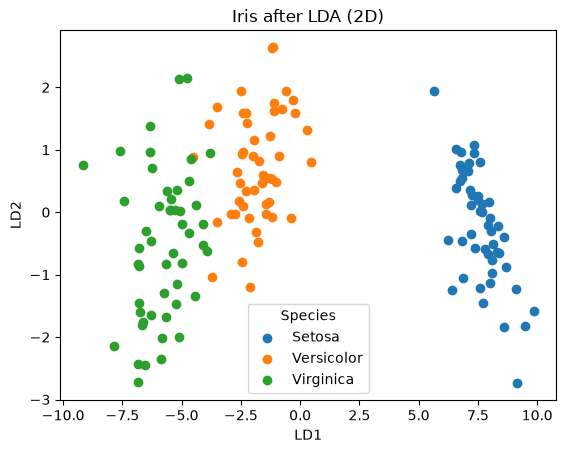

In [5]:
for i, name in enumerate(iris.target_names):
    plt.scatter(X_lda[y == i, 0], X_lda[y == i, 1], label=name.capitalize())
plt.title("Iris after LDA (2D)")
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.legend(title="Species")
plt.show()

### Q35

Apply Linear Discriminant Analysis (LDA) to the Wine dataset to reduce its dimensionality and classify the types of wine based on their chemical properties. You will visualize the LDA-reduced dataset in a 2D scatter plot and evaluate the classification performance.

Dataset: You will use the Wine dataset, which consists of 178 samples of wine, each described by 13 features representing different chemical properties. The target variable indicates the type of wine, which can take on one of three classes (1, 2, or 3).

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [7]:
# Load wine CSV: 'Wine' column is the class (1, 2, 3)
df = pd.read_csv("datasets/wine.csv")
print(df.shape)
print(df.head())
X = df.drop("Wine", axis=1)
y = df["Wine"]
print(y.value_counts().sort_index())

(178, 14)
   Wine  Alcohol  Malic.acid   Ash   Acl   Mg  Phenols  Flavanoids  \
0     1    14.23        1.71  2.43  15.6  127     2.80        3.06   
1     1    13.20        1.78  2.14  11.2  100     2.65        2.76   
2     1    13.16        2.36  2.67  18.6  101     2.80        3.24   
3     1    14.37        1.95  2.50  16.8  113     3.85        3.49   
4     1    13.24        2.59  2.87  21.0  118     2.80        2.69   

   Nonflavanoid.phenols  Proanth  Color.int   Hue    OD  Proline  
0                  0.28     2.29       5.64  1.04  3.92     1065  
1                  0.26     1.28       4.38  1.05  3.40     1050  
2                  0.30     2.81       5.68  1.03  3.17     1185  
3                  0.24     2.18       7.80  0.86  3.45     1480  
4                  0.39     1.82       4.32  1.04  2.93      735  
Wine
1    59
2    71
3    48
Name: count, dtype: int64


In [8]:
# Split and scale
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [9]:
# LDA: reduce 13 -> 2 (classes - 1 = 2) and classify
model = LinearDiscriminantAnalysis(n_components=2)
X_train_lda = model.fit_transform(X_train, y_train)
X_test_lda = model.transform(X_test)
print("Reduced shape:", X_train_lda.shape)
print("Explained variance ratio:", model.explained_variance_ratio_.round(3))

Reduced shape: (142, 2)
Explained variance ratio: [0.694 0.306]


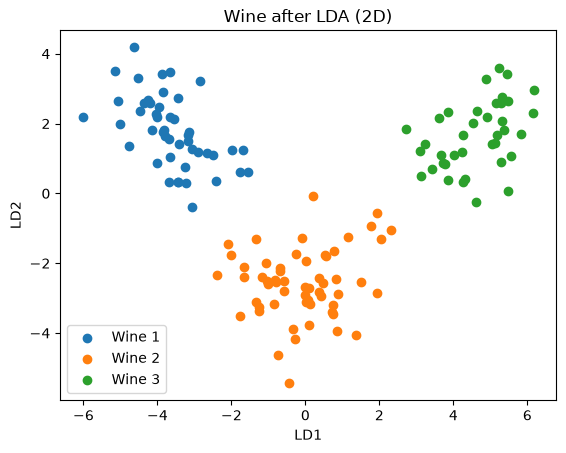

In [10]:
# 2D plot of reduced training data
for c in sorted(y.unique()):
    plt.scatter(X_train_lda[y_train == c, 0], X_train_lda[y_train == c, 1], label=f"Wine {c}")
plt.title("Wine after LDA (2D)")
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.legend()
plt.show()

Accuracy: 0.9444444444444444
              precision    recall  f1-score   support

           1       0.92      1.00      0.96        12
           2       0.93      0.93      0.93        14
           3       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



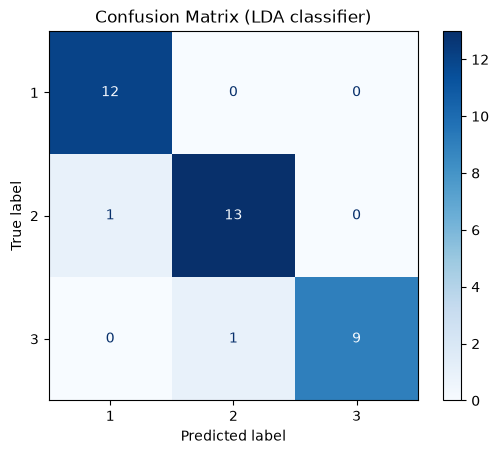

In [11]:
# Classification performance
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Confusion Matrix (LDA classifier)")
plt.show()

### Q36

apply Linear Discriminant Analysis (LDA) to the Iris dataset using the Scikit-learn library. You will preprocess the data using label encoding, perform LDA to reduce the dimensionality of the dataset, and visualize the results in a 2D scatter plot.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [13]:
# Load iris CSV (species names are text in 'variety')
df = pd.read_csv("datasets/iris.csv")
print(df.head())
X = df.drop("variety", axis=1)

   sepal.length  sepal.width  petal.length  petal.width variety
0           5.1          3.5           1.4          0.2  Setosa
1           4.9          3.0           1.4          0.2  Setosa
2           4.7          3.2           1.3          0.2  Setosa
3           4.6          3.1           1.5          0.2  Setosa
4           5.0          3.6           1.4          0.2  Setosa


In [14]:
# Label encoding: text species -> 0, 1, 2
le = LabelEncoder()
y = le.fit_transform(df["variety"])
print("Classes:", dict(zip(le.classes_, range(len(le.classes_)))))

Classes: {'Setosa': 0, 'Versicolor': 1, 'Virginica': 2}


In [15]:
# LDA to 2D
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X, y)
print("Reduced shape:", X_lda.shape)

Reduced shape: (150, 2)


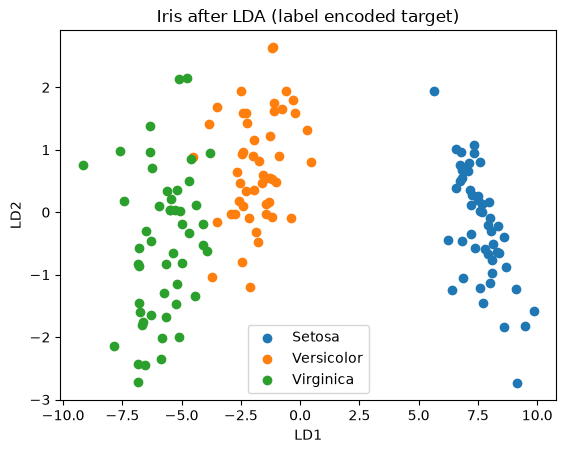

In [16]:
for i, name in enumerate(le.classes_):
    plt.scatter(X_lda[y == i, 0], X_lda[y == i, 1], label=name)
plt.title("Iris after LDA (label encoded target)")
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.legend()
plt.show()

### Q37

Objective: The goal of this practical exam is to apply Linear Discriminant Analysis (LDA) to the Breast Cancer dataset using the Scikit-learn library. You will reduce the dimensionality of the dataset from multiple features to 1 dimension and visualize the results using Matplotlib.
- load the Breast Cancer dataset
- initialize the LDA to reduce the dataset to 1 dimension.
- Fit the LDA model to the Breast Cancer dataset and transform the dataset to obtain the LDA-reduced representation.

Visualization

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [18]:
# Load CSV, drop id and empty 'Unnamed: 32' column, encode diagnosis (M = 1, B = 0)
df = pd.read_csv("datasets/Breast Cancer.csv")
df = df.drop(["id", "Unnamed: 32"], axis=1)
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"].map({"M": 1, "B": 0})
print("X shape:", X.shape)
print(df["diagnosis"].value_counts())

X shape: (569, 30)
diagnosis
B    357
M    212
Name: count, dtype: int64


In [19]:
# LDA to 1 dimension (2 classes -> max 1 component)
lda = LinearDiscriminantAnalysis(n_components=1)
X_lda = lda.fit_transform(X, y)
print("Reduced shape:", X_lda.shape)

Reduced shape: (569, 1)


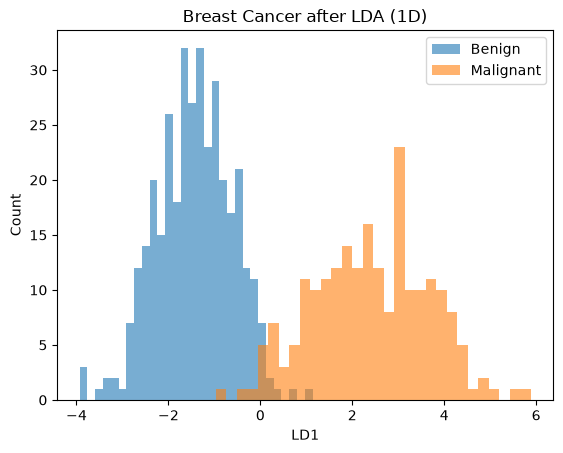

In [20]:
# Visualization 1: histogram of LD1 per class
plt.hist(X_lda[y == 0, 0], bins=30, alpha=0.6, label="Benign")
plt.hist(X_lda[y == 1, 0], bins=30, alpha=0.6, label="Malignant")
plt.title("Breast Cancer after LDA (1D)")
plt.xlabel("LD1")
plt.ylabel("Count")
plt.legend()
plt.show()

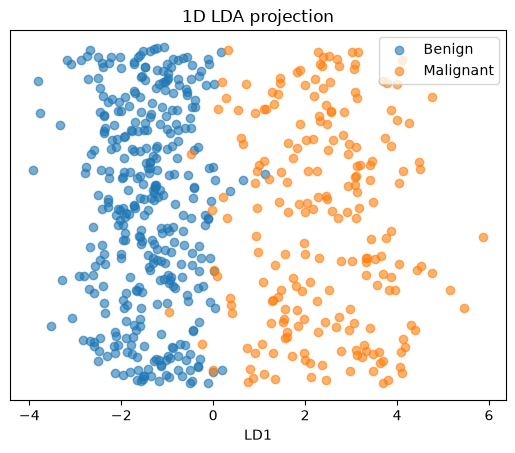

In [21]:
# Visualization 2: points on a line (small random y jitter to see overlap)
np.random.seed(42)
jitter = np.random.uniform(-0.1, 0.1, len(y))
plt.scatter(X_lda[y == 0, 0], jitter[y == 0], alpha=0.6, label="Benign")
plt.scatter(X_lda[y == 1, 0], jitter[y == 1], alpha=0.6, label="Malignant")
plt.title("1D LDA projection")
plt.xlabel("LD1")
plt.yticks([])
plt.legend()
plt.show()

### Q38

Dataset: You will use the Iris dataset, which consists of 150 samples of iris flowers, each described by 4 features (sepal length, sepal width, petal length, and petal width). The target variable indicates the species of the iris flower (Setosa, Versicolor, or Virginica). apply both Linear Discriminant Analysis (LDA) and Principal Component Analysis (PCA) to the Iris dataset. You will reduce the dimensionality of the dataset using both techniques and visualize the results in 2D scatter plots. You will then compare the effectiveness of LDA and PCA in terms of class separability.

In [22]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

In [23]:
# Load and scale
iris = load_iris()
X = StandardScaler().fit_transform(iris.data)
y = iris.target

In [24]:
# Reduce with both
X_pca = PCA(n_components=2).fit_transform(X)
X_lda = LinearDiscriminantAnalysis(n_components=2).fit_transform(X, y)

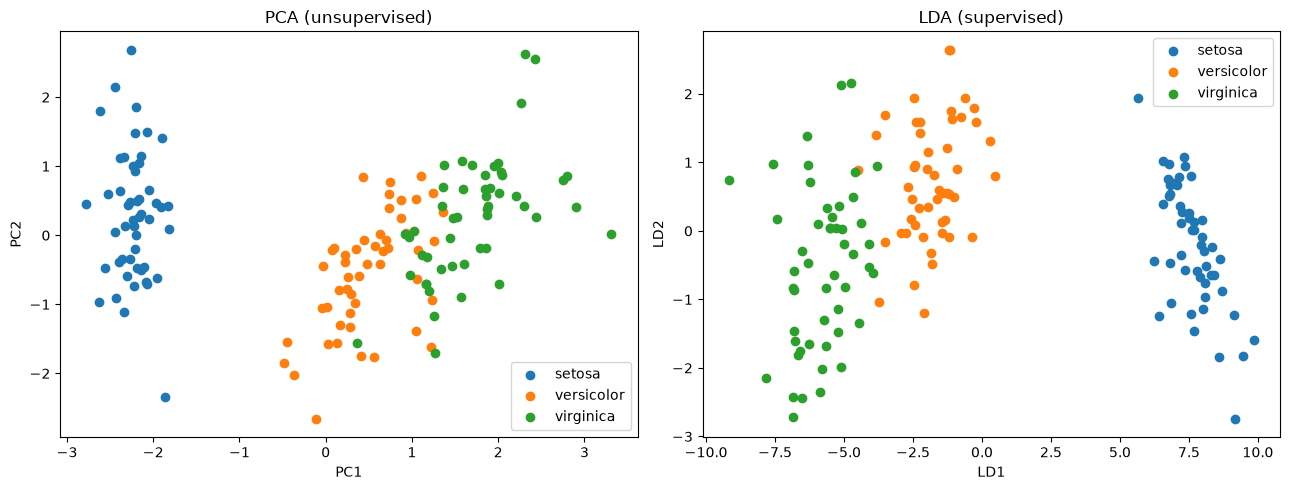

In [25]:
# Side by side plots
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for i, name in enumerate(iris.target_names):
    ax[0].scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=name)
    ax[1].scatter(X_lda[y == i, 0], X_lda[y == i, 1], label=name)
ax[0].set_title("PCA (unsupervised)")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")
ax[0].legend()
ax[1].set_title("LDA (supervised)")
ax[1].set_xlabel("LD1")
ax[1].set_ylabel("LD2")
ax[1].legend()
plt.tight_layout()
plt.show()

In [26]:
# Compare class separability with numbers
# silhouette with true labels: higher = classes better separated
# kNN 5-fold accuracy on the 2D data: higher = easier to classify
for name, Z in [("PCA", X_pca), ("LDA", X_lda)]:
    sil = silhouette_score(Z, y)
    acc = cross_val_score(KNeighborsClassifier(5), Z, y, cv=5).mean()
    print(f"{name}: silhouette = {sil:.3f}, kNN accuracy = {acc:.3f}")
# LDA uses labels and maximizes class separation, so it separates species better than PCA.

PCA: silhouette = 0.401, kNN accuracy = 0.913
LDA: silhouette = 0.646, kNN accuracy = 0.980


### Q66

Use load_wine from sklearn.datasets to load the wine dataset. initialize the LDA object with n_components=2 to reduce the dataset to 2. use matplotlib to plot the LDA-reduced dataset in 2D represented by a different color.

In [27]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [28]:
wine = load_wine()
X = wine.data
y = wine.target
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X, y)
print("Original:", X.shape, "| Reduced:", X_lda.shape)

Original: (178, 13) | Reduced: (178, 2)


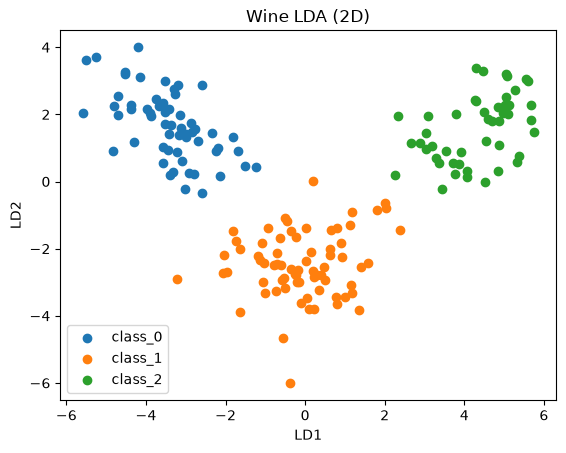

In [29]:
for i, name in enumerate(wine.target_names):
    plt.scatter(X_lda[y == i, 0], X_lda[y == i, 1], label=name)
plt.title("Wine LDA (2D)")
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.legend()
plt.show()

### Q67

Use breast cancer from sklearn.datasets to load the cancer dataset. initialize the LDA object with one component to reduce the dataset to 1D. use matplotlib to plot the LDA-reduced dataset.

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [31]:
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target                      # 0 = malignant, 1 = benign
lda = LinearDiscriminantAnalysis(n_components=1)
X_lda = lda.fit_transform(X, y)
print("Original:", X.shape, "| Reduced:", X_lda.shape)

Original: (569, 30) | Reduced: (569, 1)


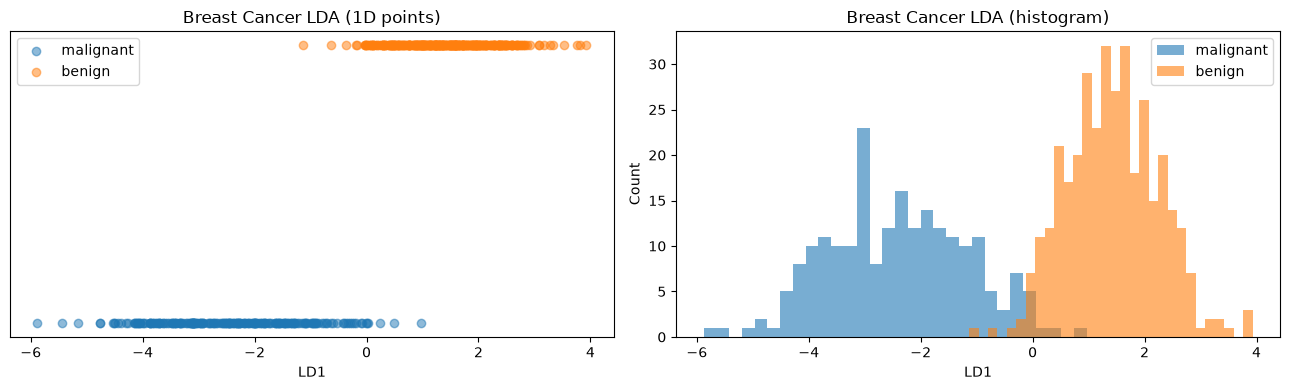

In [32]:
# 1D plot: points on a line plus histogram
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i, name in enumerate(cancer.target_names):
    ax[0].scatter(X_lda[y == i, 0], np.zeros((y == i).sum()) + i * 0.1, alpha=0.5, label=name)
    ax[1].hist(X_lda[y == i, 0], bins=30, alpha=0.6, label=name)
ax[0].set_title("Breast Cancer LDA (1D points)")
ax[0].set_xlabel("LD1")
ax[0].set_yticks([])
ax[0].legend()
ax[1].set_title("Breast Cancer LDA (histogram)")
ax[1].set_xlabel("LD1")
ax[1].set_ylabel("Count")
ax[1].legend()
plt.tight_layout()
plt.show()

### Q68

Use load_digits() from sklearn.datasets to load the hand written numbers dataset. initialize the LDA object with two component to reduce the dataset. Use matplotlib to plot the LDA-reduced dataset.

In [33]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [34]:
digits = load_digits()
X = digits.data           # 1797 images, 64 pixel features
y = digits.target         # digits 0..9
lda = LinearDiscriminantAnalysis(n_components=2)   # max allowed = 10 - 1 = 9
X_lda = lda.fit_transform(X, y)
print("Original:", X.shape, "| Reduced:", X_lda.shape)

Original: (1797, 64) | Reduced: (1797, 2)


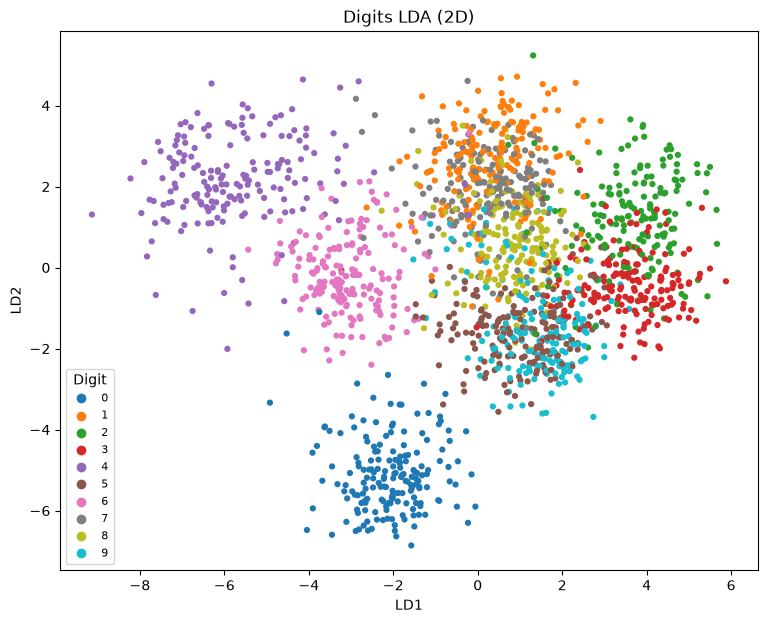

In [35]:
plt.figure(figsize=(9, 7))
sc = plt.scatter(X_lda[:, 0], X_lda[:, 1], c=y, cmap="tab10", s=12)
plt.legend(*sc.legend_elements(), title="Digit", loc="best", fontsize=8)
plt.title("Digits LDA (2D)")
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.show()

### Q69

Use load_iris from sklearn.datasets to load the Iris dataset. initialize the LDA object with n_components=2 to reduce the dataset to 2. use matplotlib to plot the LDA-reduced dataset in 2D.

In [36]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [37]:
iris = load_iris()
X = iris.data
y = iris.target
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X, y)
print("Original:", X.shape, "| Reduced:", X_lda.shape)

Original: (150, 4) | Reduced: (150, 2)


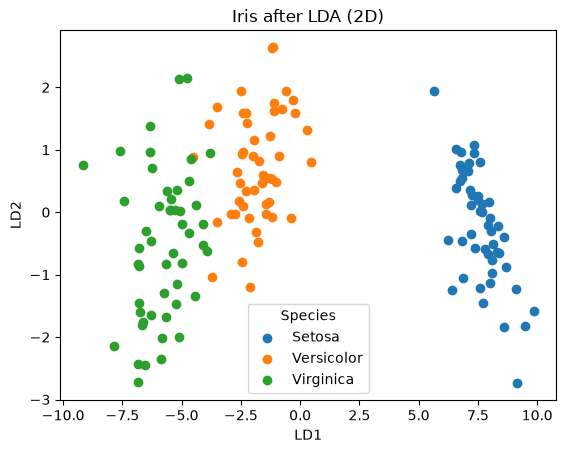

In [38]:
for i, name in enumerate(iris.target_names):
    plt.scatter(X_lda[y == i, 0], X_lda[y == i, 1], label=name.capitalize())
plt.title("Iris after LDA (2D)")
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.legend(title="Species")
plt.show()